In [ ]:
import numpy as np
import pandas as pd

In [ ]:
import kagglehub

path = kagglehub.dataset_download("uditjain13/credit-card-fraud-detection-2026", output_dir='./sample_data')

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'credit-card-fraud-detection-2026' dataset.
Path to dataset files: /kaggle/input/credit-card-fraud-detection-2026


# Credit Card Fraud Detection 2026
Набор данных для обнаружения мошеннических транзакций по кредитным картам (Бинарная классификация)

Ссылка на Kaggle: https://www.kaggle.com/datasets/uditjain13/credit-card-fraud-detection-2026/data


In [ ]:
data = pd.read_csv('/kaggle/input/credit-card-fraud-detection-2026/credit_card_fraud_2026.csv', delimiter=',')
data.head()

,transaction_id,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,...,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes,is_fraud
0,1,42.86,Restaurants,Visa,OTP,Online,Android Phone,False,13.54,2,...,False,False,0,0.1,18,3,False,42.3,0,0
1,2,4.75,Online Retail,Mastercard,3D Secure,Online,Android Phone,False,0.71,2,...,False,False,0,25.8,12,4,False,28.3,0,0
2,3,77.18,Groceries,Mastercard,3D Secure,Online,Mac,False,0.35,5,...,False,True,0,42.3,5,0,False,24.7,1,0
3,4,1.69,Streaming,Visa,No Authentication,POS,Android Phone,False,3.42,6,...,False,False,0,28.9,22,6,False,56.2,1,0
4,5,261.68,Travel,Visa,3D Secure,In-App,iPhone,False,2.43,2,...,False,False,0,3.9,2,4,False,32.7,0,0


В датасете 20000 объектов, 26 показателей у каждого.

In [ ]:
data.shape

(20000, 26)

Причем последний показатель ``is_fraud`` является целевой переменной (*target*).
Виден дисбаланс классов, который мы визуализируем позже.



In [ ]:
data['is_fraud'].value_counts()

,count
is_fraud,
0,19661
1,339


In [ ]:
data["amount_usd"].describe()

,amount_usd
count,20000.000000
mean,132.424597
std,256.963666
min,1.000000
25%,26.235000
50%,57.510000
75%,131.752500
max,6872.690000


# Описание показателей
Распределим показатели на шкалы и отобразим их характеристики.

In [ ]:
quantitative = data.select_dtypes(include=["number"]).columns.tolist()
qualitative = data.select_dtypes(exclude=["number"]).columns.tolist()

# Признаки, которые считаем качественными, несмотря на числовой формат
qualitative_extra = [
    "transaction_id",
    "time_of_day_hour",
    "day_of_week",
    "is_fraud"
]

for param in qualitative_extra:
    if param in quantitative:
        quantitative.remove(param)

quantitative_table = data[quantitative].describe().T
quantitative_table["шкала"] = "количественный"

qualitative_table = data[qualitative].describe().T
qualitative_table["шкала"] = "качественный"

qualitative_extra_table = data[qualitative_extra].describe().T
qualitative_extra_table["шкала"] = "номинальный"
qualitative_extra_table.loc["time_of_day_hour", "шкала"] = "интервальный"

## Количественные показатели

Каждый показатель описан следующими параметрами:

``mean`` - среднее арифметическое по всем объектам датасета

``std`` - среднеквадратичное отклонение

Показатель находится в интервале [``min``, ``max``]

Также приведены 1, 2, 3 квартили распределения показателя

In [ ]:
quantitative_table

,count,mean,std,min,25%,50%,75%,max,шкала
amount_usd,20000.0,132.424597,256.963666,1.00,26.2350,57.510,131.7525,6872.69,количественный
hours_since_last_txn,20000.0,8.950827,8.838745,0.01,2.5900,6.210,12.4325,87.05,количественный
txn_count_last_24h,20000.0,3.191650,1.779544,0.00,2.0000,3.000,4.0000,12.00,количественный
distance_from_home_km,20000.0,22.139525,22.120960,0.00,6.3375,15.505,30.8200,216.19,количественный
card_age_months,20000.0,46.937550,6.768577,22.00,42.0000,47.000,51.0000,74.00,количественный
customer_age,20000.0,49.669400,18.494032,18.00,34.0000,50.000,66.0000,81.00,количественный
account_balance_usd,20000.0,3316.662598,4350.720948,52.05,1019.1400,2007.685,3944.1200,127125.86,количественный
cvv_retry_count,20000.0,0.181300,0.422302,0.00,0.0000,0.000,0.0000,3.00,количественный
velocity_score,20000.0,19.807735,12.366301,0.00,10.7000,18.800,27.6000,74.40,количественный
merchant_risk_score,20000.0,37.400390,17.061415,0.00,25.6000,35.700,47.3000,100.00,количественный


## Качественные показатели

За количество возможных значений отвечает столбец ``unique``

За моду отвечает столбец ``top``

``freq`` хранит частоту моды, то есть сколько раз встречается самое частое значение

Заметим, что 6 из 11 качественных показателей являются типа ``bool``

In [ ]:
qualitative_table

,count,unique,top,freq,шкала
merchant_category,20000,12,Online Retail,3416,качественный
card_type,20000,5,Visa,8417,качественный
auth_method,20000,5,3D Secure,5554,качественный
channel,20000,5,Online,6810,качественный
device_type,20000,8,Android Phone,5503,качественный
is_foreign_transaction,20000,2,False,18760,качественный
is_new_merchant,20000,2,False,15399,качественный
used_vpn,20000,2,False,18241,качественный
ip_country_mismatch,20000,2,False,18834,качественный
billing_shipping_mismatch,20000,2,False,19127,качественный


Вынесем номинальные/интервальные (качественные) показатели в отдельную таблицу, несмотря на числовую шкалу

In [ ]:
qualitative_extra_table

,count,mean,std,min,25%,50%,75%,max,шкала
transaction_id,20000.0,10000.50000,5773.647028,1.0,5000.75,10000.5,15000.25,20000.0,номинальный
time_of_day_hour,20000.0,11.53365,6.925335,0.0,6.00,12.0,18.00,23.0,интервальный
day_of_week,20000.0,2.99875,2.004956,0.0,1.00,3.0,5.00,6.0,номинальный
is_fraud,20000.0,0.01695,0.129087,0.0,0.00,0.0,0.00,1.0,номинальный


# Визуализация показателей

Отразим дисбаланс классов в виде **Круговой диаграммы (Pie Chart)**

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

Видим все тот же **дисбаланс классов**:

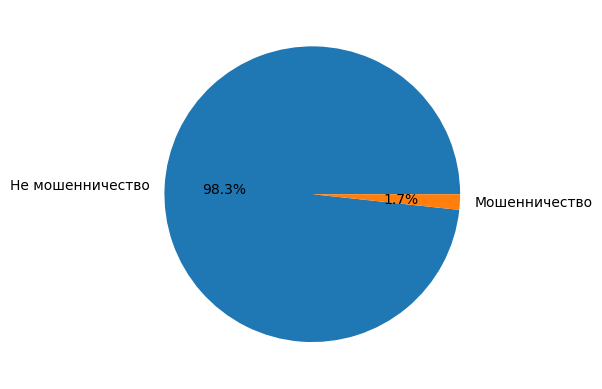

In [ ]:
counts = data["is_fraud"].value_counts()

plt.pie(
    counts,
    labels=["Не мошенничество", "Мошенничество"],
    autopct="%1.1f%%"
)
plt.show()

Отразим **частотную диаграмму** по сферам покупок (транзакций)

<Axes: xlabel='merchant_category', ylabel='count'>

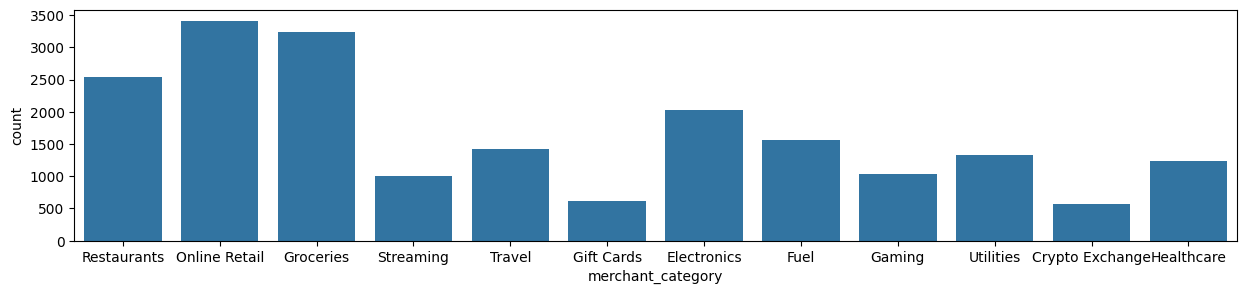

In [ ]:
fig = plt.figure(figsize = (15, 3))
sns.countplot(x="merchant_category", data = data)

Выведем по 2 графика (гистограмма и boxplot) на каждый из трех параметров:


*   Возраст покупателя
*   Цена покупки (в долларах США)
*   Расстояние от дома при покупке



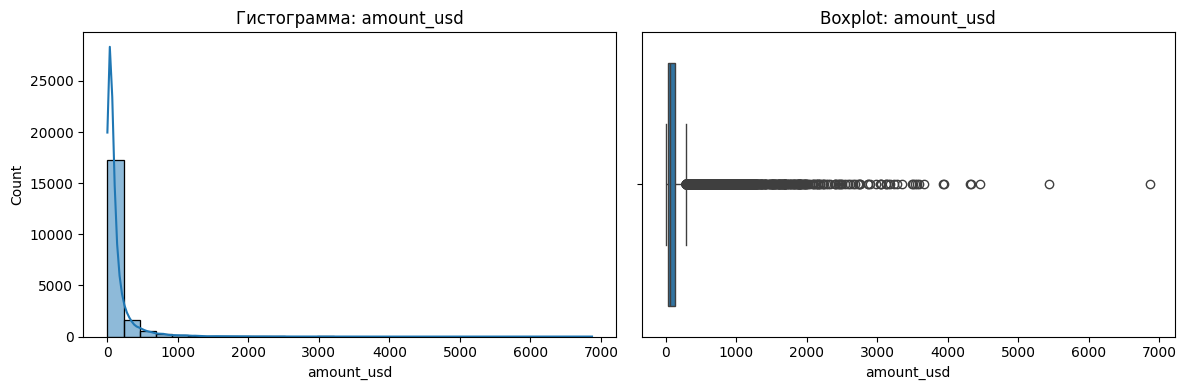

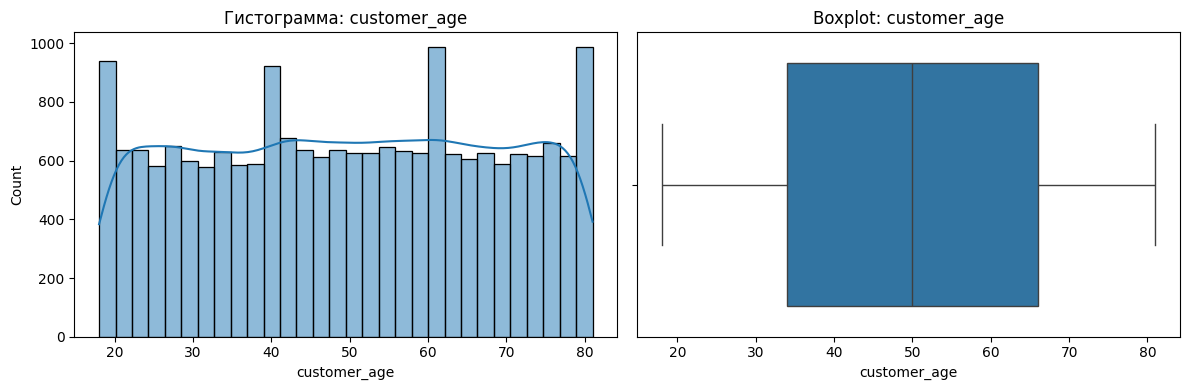

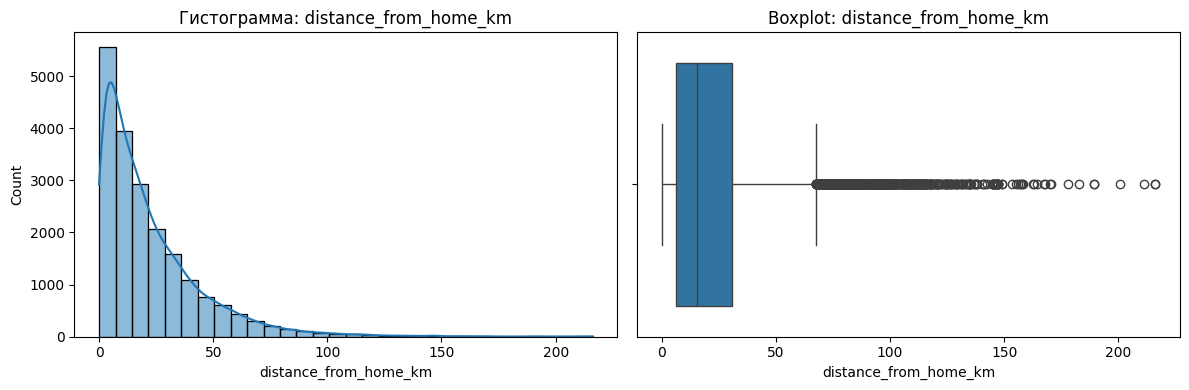

In [ ]:
quant_plot = ['amount_usd', 'customer_age', 'distance_from_home_km']

for col in quant_plot:
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    sns.histplot(data[col], kde=True, bins=30)
    plt.title(f'Гистограмма: {col}')

    plt.subplot(1, 2, 2)
    sns.boxplot(x=data[col])
    plt.title(f'Boxplot: {col}')

    plt.tight_layout()
    plt.show()

Видим, что:


1.   Покупки в основном совершаются **близко к дому (вероятно в городе проживания)**
2.   Возраст распределен практически равномерно **от ~18 до ~82 ле**т, однако есть лидирующие группы: молодые люди до 20 лет, люди около 40 лет, около 62 и в районе 80

3.  Большая часть покупок совершена с суммой **много меньше 1000 долларов**, однако присутствуют выбросы



Теперь выведем частотные диаграммы для качественных показателей:


*   Тип платежной системы
*   Способ оплаты
*   Способ аутентификации



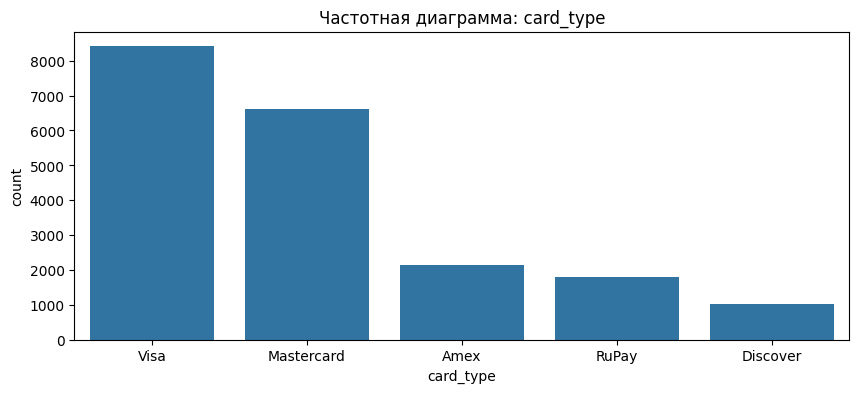

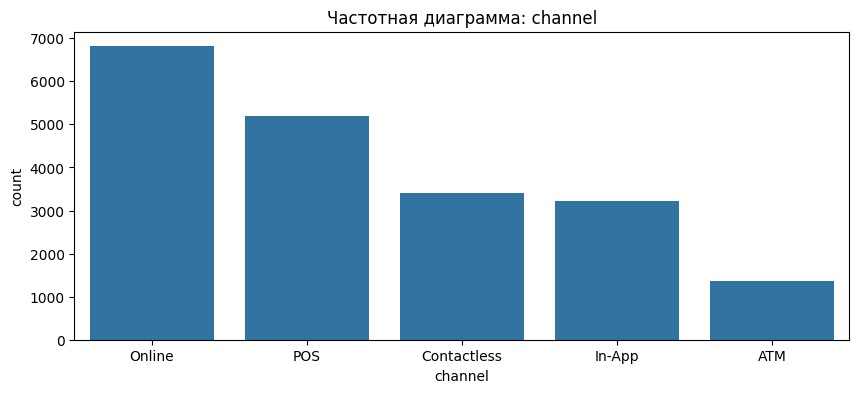

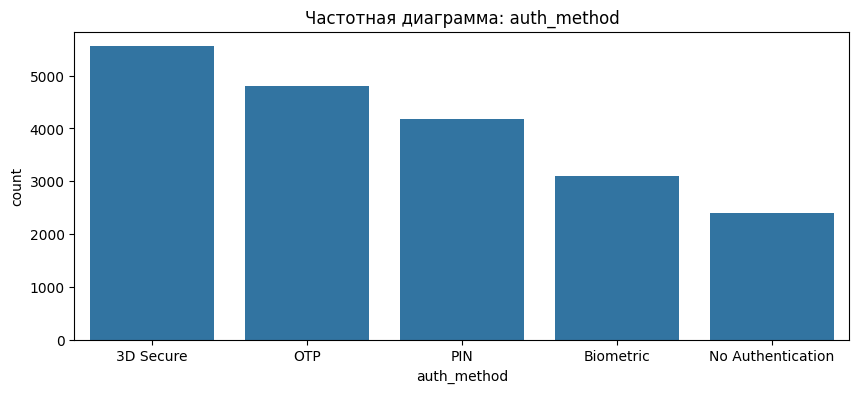

In [ ]:
qual_plot = ['card_type', 'channel', 'auth_method']

for col in qual_plot:
    plt.figure(figsize=(10, 4))
    sns.countplot(
        data=data,
        x=col,
        order=data[col].value_counts().index
    )
    plt.title(f'Частотная диаграмма: {col}')
    plt.show()

Видим, что лидирующие в каждом показателе:


*   Visa и Mastercard как платежные системы
*   Онлайн покупки
*   3D Secure аутентификация



# Группировка объектов
Вычислим средние значения по количественным показателям для мошеннических и немошеннических переводов.

In [ ]:
group_means = data.groupby('is_fraud')[quantitative].mean().T
group_means.columns = [f'is_fraud={c}' for c in group_means.columns]
group_means['diff'] = (group_means.iloc[:, 1] - group_means.iloc[:, 0]).abs()

group_means_sorted = group_means.sort_values('diff', ascending=False)
display(group_means_sorted)

top_quant = group_means_sorted.index[0]
print(f'\nНаибольшая разница средних значений: {top_quant}')

,is_fraud=0,is_fraud=1,diff
account_balance_usd,3314.165282,3461.499558,147.334275
amount_usd,131.582739,181.249853,49.667113
merchant_risk_score,37.159158,51.391150,14.231993
velocity_score,19.649814,28.966667,9.316852
customer_age,49.621942,52.421829,2.799887
hours_since_last_txn,8.984251,7.012389,1.971861
txn_count_last_24h,3.177661,4.002950,0.825288
distance_from_home_km,22.151991,21.416490,0.735502
card_age_months,46.948273,46.315634,0.632639
cvv_retry_count,0.172677,0.681416,0.508739



Наибольшая разница средних значений: account_balance_usd


Наибольшая разница средних значений оказалась у показателя суммы на балансе.

Отобразим диаграммы размаха для классов по этому показателю.

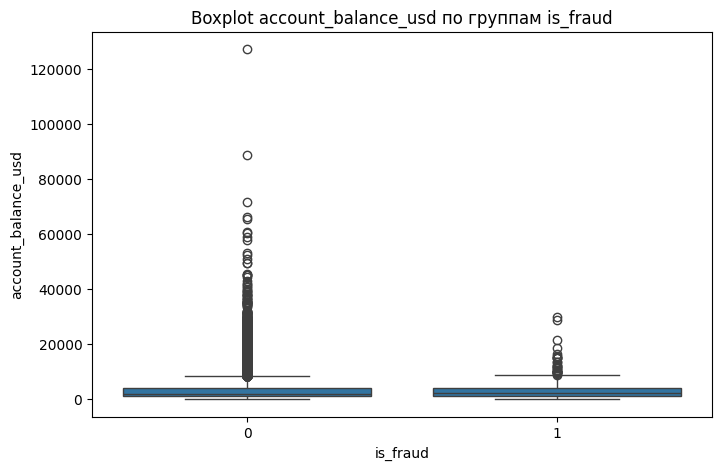

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x='is_fraud', y=top_quant)
plt.title(f'Boxplot {top_quant} по группам is_fraud')
plt.show()

Уже видим, что мошеннические переводы ограничиваются небольшой суммой баланса карты, но стоит попробовать воспользоваться логарифмической шкалой для хорошей визуализации.

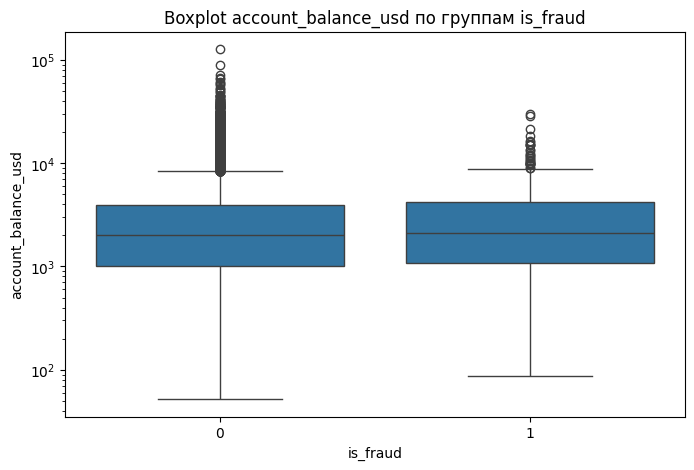

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x='is_fraud', y=top_quant)
plt.title(f'Boxplot {top_quant} по группам is_fraud')
plt.yscale('log')
plt.show()

В большинстве случаев баланс карт не отличается, но на графике видно, что мошенники не рискуют реализовывать транзакции с большими суммами.

Воспользуемся индексом диссимиляции (см. https://en.wikipedia.org/wiki/Qualitative_variation#Index_of_dissimilarity) для каждого качественного признака, чтобы вывести признак, обладающей наибольшей разницей для выделенных групп.

In [ ]:
def freq_diff(col):
    cross_table = pd.crosstab(data[col], data['is_fraud'], normalize='columns')
    if cross_table.shape[1] < 2:
        return np.nan
    return 0.5 * (cross_table.iloc[:, 1] - cross_table.iloc[:, 0]).abs().sum()

freq_diffs = pd.Series(
    {col: freq_diff(col) for col in qualitative}
).sort_values(ascending=False)

display(freq_diffs)

top_qual = freq_diffs.index[0]
print(f'Наибольшая разница частот: {top_qual}')

,0
is_new_merchant,0.249098
merchant_category,0.226156
ip_country_mismatch,0.213760
auth_method,0.196617
billing_shipping_mismatch,0.159646
is_foreign_transaction,0.155983
used_vpn,0.141589
is_ai_generated_scam_attempt,0.082951
channel,0.063859
device_type,0.051894


Наибольшая разница частот: is_new_merchant


Получили признак, различающий новых продавцов, от старых.

# Визуализация зависимостей показателей

Покажем зависимость количественных признаков:


*   Сумма транзакции (в долларах США)
*   Возраст покупателя



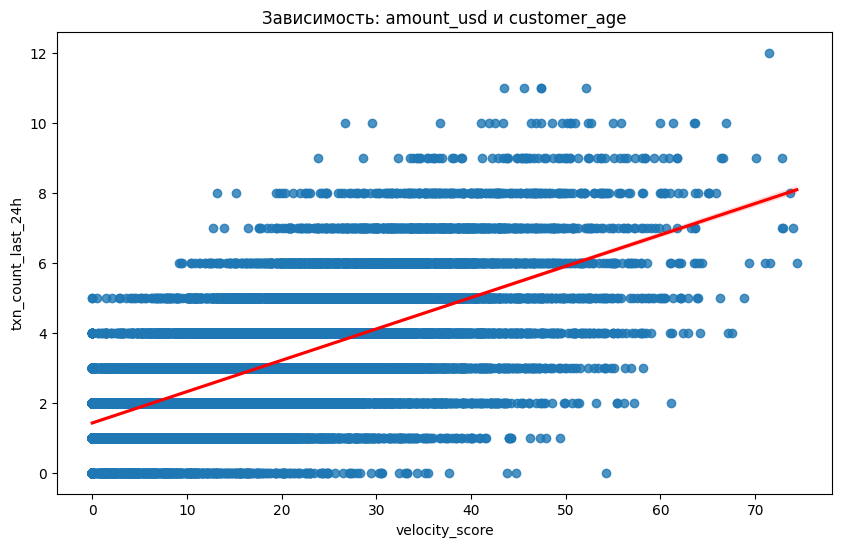

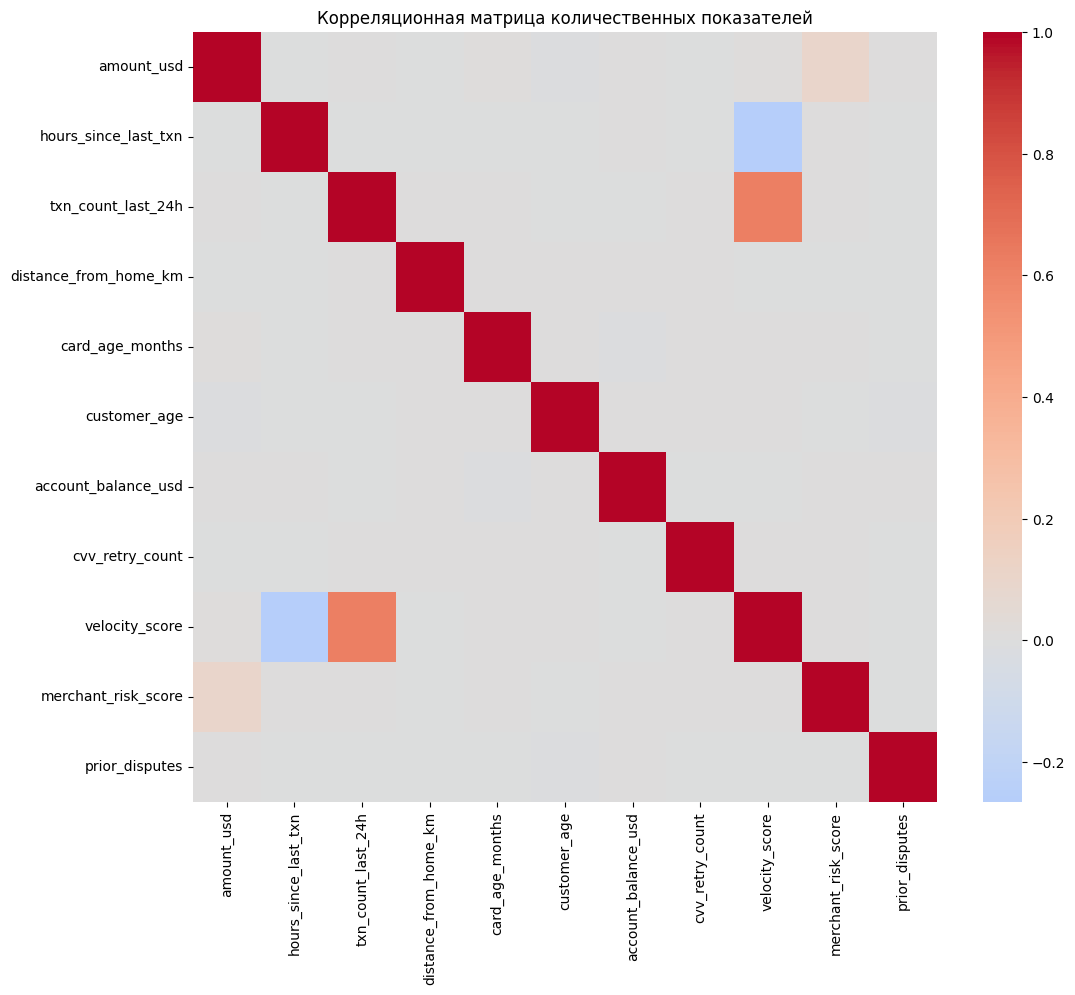

In [ ]:
plt.figure(figsize=(10, 6))
sns.regplot(
    data=data,
    x='velocity_score',
    y='txn_count_last_24h',
    line_kws={'color': 'red'}
)
plt.title('Зависимость: amount_usd и сustomer_age')
plt.show()

plt.figure(figsize=(12, 10))
sns.heatmap(
    data[quantitative].corr(),
    cmap='coolwarm',
    center=0,
    annot=False
)
plt.title('Корреляционная матрица количественных показателей')
plt.show()

С помощью RegPlot показали корреляцию показателя **скорости покупок** и показателя **количества транзакций за последние 24 часа**.

Дополнительно убедились в сильной зависимости с помощью тепловой карты (HeatMap), поэтому в будущем можно будет избавиться от одного из показателей путем регуляризации: L1 или L2.

Покажем

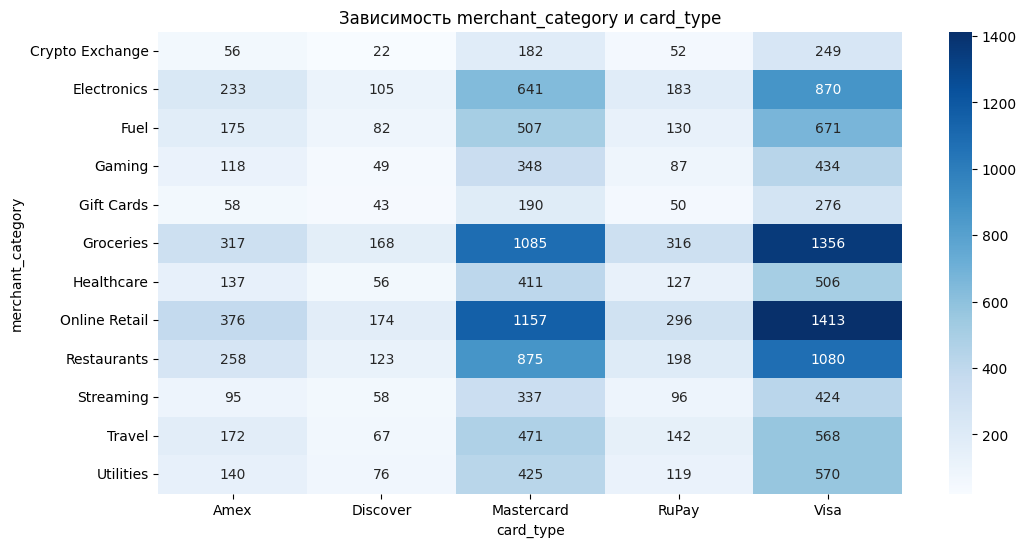

In [ ]:
ct = pd.crosstab(data['merchant_category'], data['card_type'])

plt.figure(figsize=(12, 6))
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues')
plt.title('Зависимость merchant_category и card_type')
plt.show()

Видим, что покупки у онлайн продавцов совершают больше с Visa и MasterCard.

Сгруппируем количественны и качественный признаки:


*   Категория продавца
*   Процент риска продавца (ненадежность)



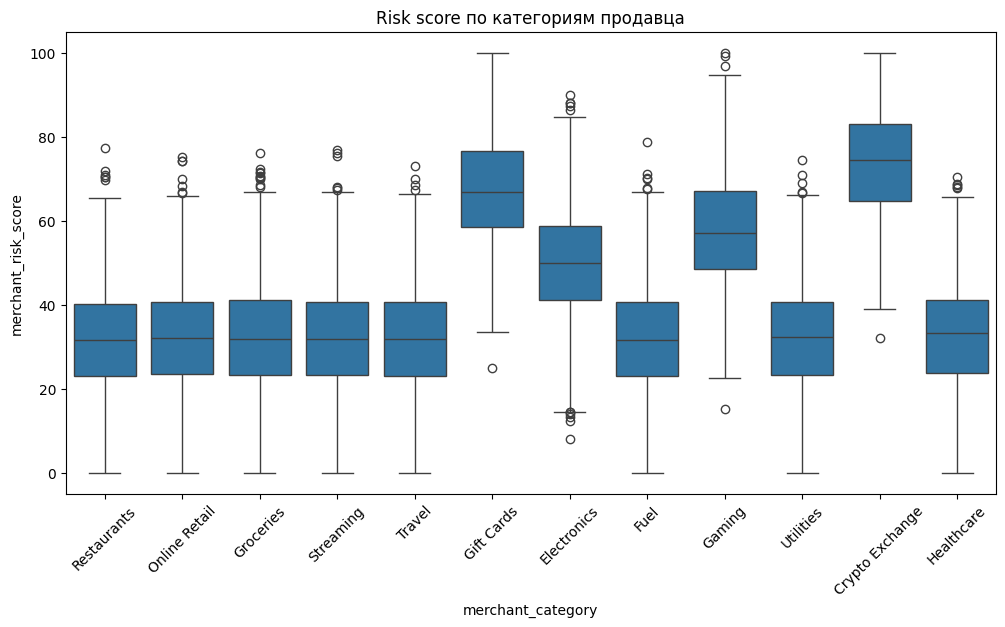

In [ ]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=data, x='merchant_category', y='merchant_risk_score')
plt.xticks(rotation=45)
plt.title('Risk score по категориям продавца')
plt.show()

Видим, что обмены криптовалютой и подарочные карты считаются ненадежными категориями продаж, тогда как рестораны, магазины, подписки на сервисы, топливо и медицина считаются надежными категориями.


# Пропуски данных и аномальные выбросы

In [ ]:
missing = data.isna().sum().sort_values(ascending=False)
if (missing > 0).any():
    display(missing[missing > 0])
else:
    print('Пропусков нет')

Пропусков нет


Так как пропусков в исходном датасете нет, мы создадим их искуственно.

In [ ]:
np.random.seed(42)

data_with_na = data.copy()

quant_with_na = ['amount_usd', 'account_balance_usd', 'customer_age', 'velocity_score']

for col in quant_with_na:
    idx = np.random.choice(data_with_na.index,
                           size=int(0.05 * len(data_with_na)),
                           replace=False)
    data_with_na.loc[idx, col] = np.nan

qual_with_na = ['card_type', 'channel', 'merchant_category']

for col in qual_with_na:
    idx = np.random.choice(data_with_na.index,
                           size=int(0.03 * len(data_with_na)),
                           replace=False)
    data_with_na.loc[idx, col] = np.nan

print('Размер до обработки:', data_with_na.shape)

Размер до обработки: (20000, 26)


In [ ]:
missing = data_with_na.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print('Пропуски по показателям:')
display(missing)

print(f'Всего строк с хотя бы одним пропуском: '
      f'{data_with_na.isna().any(axis=1).sum()}')

print(f'Всего ячеек с пропусками: {data_with_na.isna().sum().sum()}')

Пропуски по показателям:


,0
amount_usd,1000
account_balance_usd,1000
customer_age,1000
velocity_score,1000
merchant_category,600
card_type,600
channel,600


Всего строк с хотя бы одним пропуском: 5111
Всего ячеек с пропусками: 5800


In [ ]:
data_clean = data_with_na.dropna()

print('После dropna (по строкам):', data_clean.shape)
print(f'Удалено строк: {data_with_na.shape[0] - data_clean.shape[0]}')
print(f'Осталось пропусков: {data_clean.isna().sum()}')

После dropna (по строкам): (14889, 26)
Удалено строк: 5111
Осталось пропусков: transaction_id                  0
amount_usd                      0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
is_new_merchant                 0
used_vpn                        0
ip_country_mismatch             0
billing_shipping_mismatch       0
cvv_retry_count                 0
velocity_score                  0
time_of_day_hour                0
day_of_week                     0
is_ai_generated_scam_attempt    0
merchant_risk_score             0
prior_disputes                  0
is_fraud                        0
dtype: int64


Воспользовались dropna() для удаления поврежденных строк.

Для обнаружения выбросов воспользуемся IQR.

In [ ]:
def outlier_count(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return ((series < lower) | (series > upper)).sum()

outliers = pd.Series(
    {col: outlier_count(data[col]) for col in quantitative}
).sort_values(ascending=False)
display(outliers)

,0
prior_disputes,4915
cvv_retry_count,3342
amount_usd,2061
account_balance_usd,1569
hours_since_last_txn,955
distance_from_home_km,904
merchant_risk_score,358
txn_count_last_24h,336
velocity_score,213
card_age_months,177
